# Exercise 2 — Fine-tuning DistilBERT for Binary Text Classification

**Report notebook (read-only):** loads locally produced artifacts; it does **not** download a model, train or fabricate results. Open it from the `exercise_2/` folder after running the scripts in `README.md`.

**Student:** [fill in] · **Date:** [fill in] · **Run:** `lan_1` (edit below).


## 1. Aim and acceptance checklist

Install Transformers/Datasets/Evaluate, load IMDb, load tokenizer/model, preprocess, define TrainingArguments, fine-tune with Trainer and evaluate.

Data split: train/validation from official IMDb train, reserved test from official IMDb test. See `Experiment_Plan.md` and `docs/`.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if (ROOT / "exercise_2").exists():
    ROOT = ROOT / "exercise_2"
RUN = 'lan_1'  # change to your completed run
run = ROOT / 'outputs' / 'runs' / RUN

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None

print("Folder:", ROOT.name)
print('Run:', RUN, '| Complete:', (run / 'TRAINING_COMPLETE').exists())


Folder: exercise_2
Run: lan_1 | Complete: True


## 3. Dataset, labels and split integrity

The only labeled classes are 0=NEGATIVE and 1=POSITIVE. Report selected subset counts and SHA256; test is not used for checkpoint selection.

In [2]:
split = read_json(ROOT / 'outputs' / 'data' / 'split_info.json')
if split is None:
    print('No prepared data. Run src/2_preparedata.py.')
else:
    print('Dataset:', split.get('dataset_id'))
    print('Seed:', split.get('seed'), 'Max length:', split.get('max_length'))
    display(pd.DataFrame([{'split':k, **v['labels'], 'n':v['count'], 'sha256':v['text_label_sha256'][:16]+'…'}
                          for k,v in split['splits'].items()]))


Dataset: stanfordnlp/imdb
Seed: 42 Max length: 128


,split,NEGATIVE,POSITIVE,n,sha256
0,train,993,1007,2000,4699197586d4371c…
1,validation,199,201,400,e768f624b5d2ce07…
2,test,254,246,500,4b9e8123673e9a5f…


## 4. Fine-tuning configuration and selected run

Fine-tune `distilbert-base-uncased` for binary classification. A new head emits two logits per review, and Trainer handles forward, cross entropy, backward and optimizer steps.

In [3]:
cfg = read_json(run / 'config.json')
if cfg is None:
    print('No configuration found. Training may not have started.')
else:
    for k in ('base_model','dataset_id','seed','train_samples','validation_samples','max_length',
              'epochs','batch_size','learning_rate','weight_decay','best_checkpoint','best_metric'):
        print(f'{k}: {cfg.get(k, "not recorded")}')


base_model: distilbert/distilbert-base-uncased
dataset_id: stanfordnlp/imdb
seed: 42
train_samples: 2000
validation_samples: 400
max_length: 128
epochs: 3
batch_size: 8
learning_rate: 2e-05
weight_decay: 0.01
best_checkpoint: C:\Users\hovan\Downloads\practice_31\practice_3_split\exercise_2\outputs\runs\lan_1\checkpoints\checkpoint-500
best_metric: 0.8660287081339713


## 5. Train and validation evidence

Read the actual Trainer history and run summaries. Empty outputs mean **not measured**, not zero. Differentiate training and validation losses.

In [4]:
history = read_json(run / 'history.json')
if history is None:
    print('history.json absent. No completed training history to report.')
else:
    interesting = ['epoch','step','loss','eval_loss','eval_accuracy','eval_precision','eval_recall','eval_f1','learning_rate']
    table = pd.DataFrame(history)
    display(table[[c for c in interesting if c in table.columns]].tail(20))
    print('Actual history rows:',len(table))
print('Training:', read_json(run / 'train_metrics.json'))
print('Validation:', read_json(run / 'validation_metrics.json'))


,epoch,step,loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,learning_rate
0,1.0,250,0.519042,NaN,NaN,NaN,NaN,NaN,1.336000e-05
1,1.0,250,NaN,0.390260,0.835,0.777778,0.940299,0.851351,NaN
2,2.0,500,0.279353,NaN,NaN,NaN,NaN,NaN,6.693333e-06
3,2.0,500,NaN,0.431398,0.860,0.834101,0.900498,0.866029,NaN
4,3.0,750,0.177553,NaN,NaN,NaN,NaN,NaN,2.666667e-08
5,3.0,750,NaN,0.507956,0.860,0.857143,0.865672,0.861386,NaN
6,3.0,750,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,3.0,750,NaN,0.431398,0.860,0.834101,0.900498,0.866029,NaN


Actual history rows: 8
Training: {'train_runtime': 980.0916, 'train_samples_per_second': 6.122, 'train_steps_per_second': 0.765, 'total_flos': 198701097984000.0, 'train_loss': 0.3253161977132161, 'epoch': 3.0}
Validation: {'eval_loss': 0.4313976764678955, 'eval_accuracy': 0.86, 'eval_precision': 0.8341013824884793, 'eval_recall': 0.900497512437811, 'eval_f1': 0.8660287081339713, 'eval_runtime': 16.0379, 'eval_samples_per_second': 24.941, 'eval_steps_per_second': 3.118, 'epoch': 3.0}


## 6. Final independent evaluation

`validation_recheck.json` is not the same as `test_metrics.json`. The final test should be run once after selection is frozen, and evidence must identify the split.

In [5]:
test = read_json(run / 'test_metrics.json')
val = read_json(run / 'validation_recheck.json')
evidence = test if test is not None else val
if evidence is None:
    print('No prediction-level evaluation. Run 4_evaluate.py on validation first.')
else:
    print('Split:', evidence.get('split'), '| count:', evidence.get('sample_count'))
    display(pd.Series(evidence.get('metrics', {}),name='metric').to_frame())
    print('ROC-AUC:',evidence.get('roc_auc'))
    if evidence.get('classification_report'):
        display(pd.DataFrame(evidence['classification_report']).T)
    print('Confusion matrix (rows actual; columns predicted):',evidence.get('confusion_matrix'))


Split: test | count: 500


,metric
test_loss,0.537101
test_model_preparation_time,0.001000
test_accuracy,0.812000
test_precision,0.755034
test_recall,0.914634
test_f1,0.827206
test_runtime,28.565100
test_samples_per_second,17.504000
test_steps_per_second,2.205000


ROC-AUC: 0.9164746175020805


,precision,recall,f1-score,support
NEGATIVE,0.896040,0.712598,0.793860,254.000
POSITIVE,0.755034,0.914634,0.827206,246.000
accuracy,0.812000,0.812000,0.812000,0.812
macro avg,0.825537,0.813616,0.810533,500.000
weighted avg,0.826665,0.812000,0.810266,500.000


Confusion matrix (rows actual; columns predicted): [[181, 73], [21, 225]]


## 7. Generated figures

Render `loss.png`, `validation_scores.png`, and `confusion_matrix.png` only when `5_report.py` has created them from real artifacts.

**loss.png**

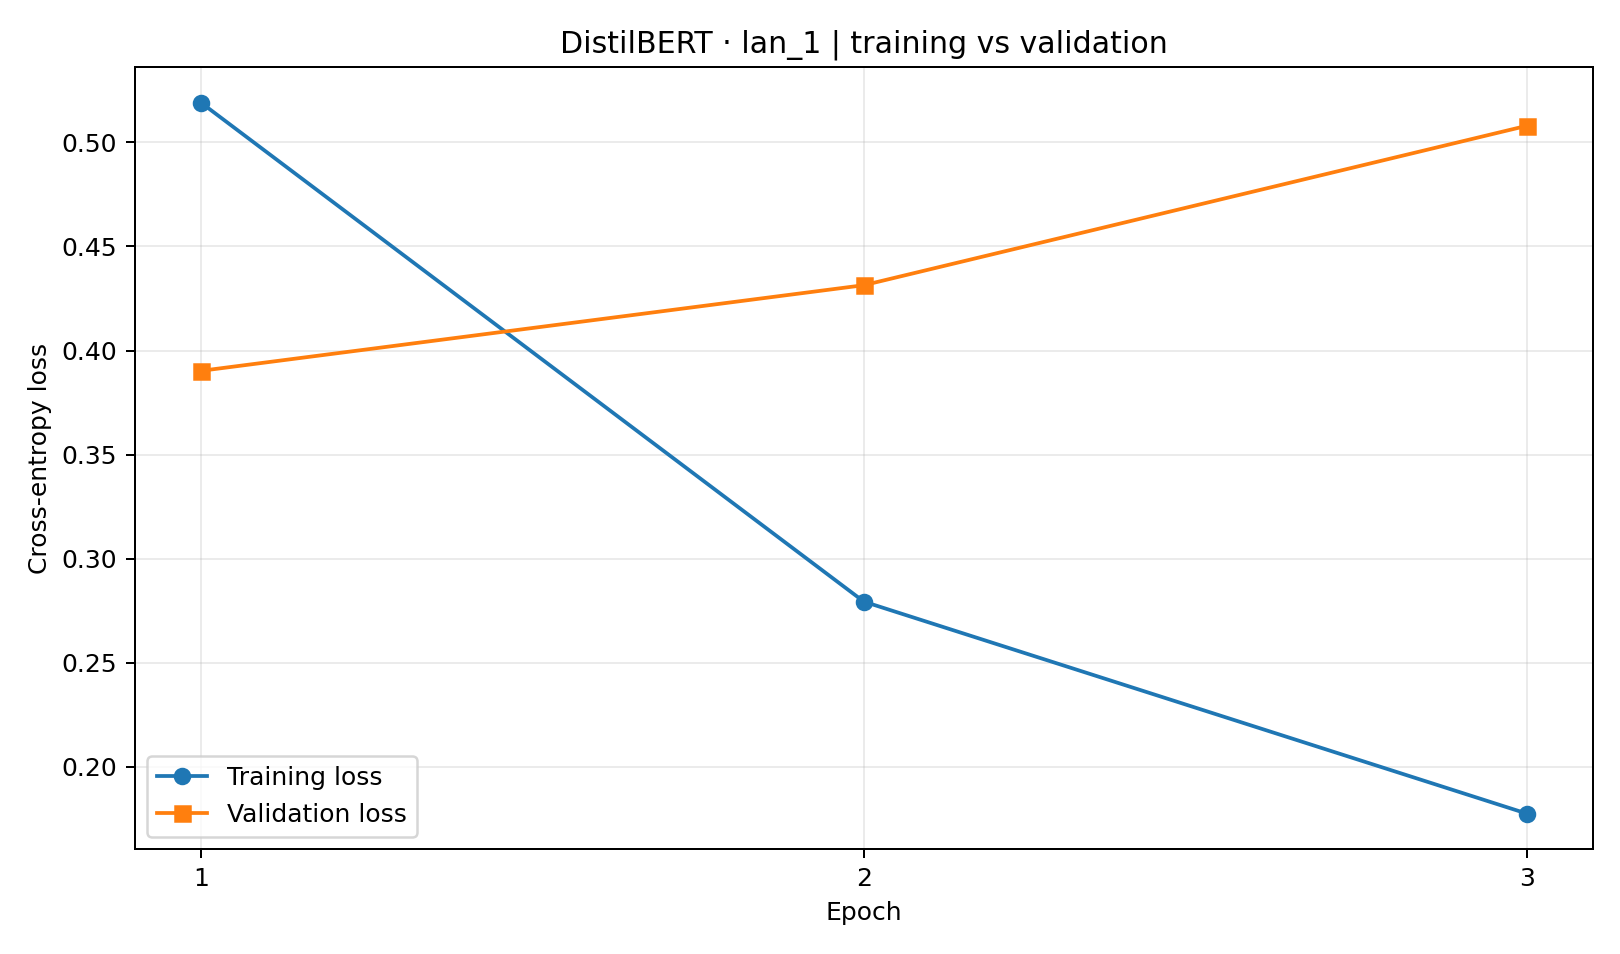

**validation_scores.png**

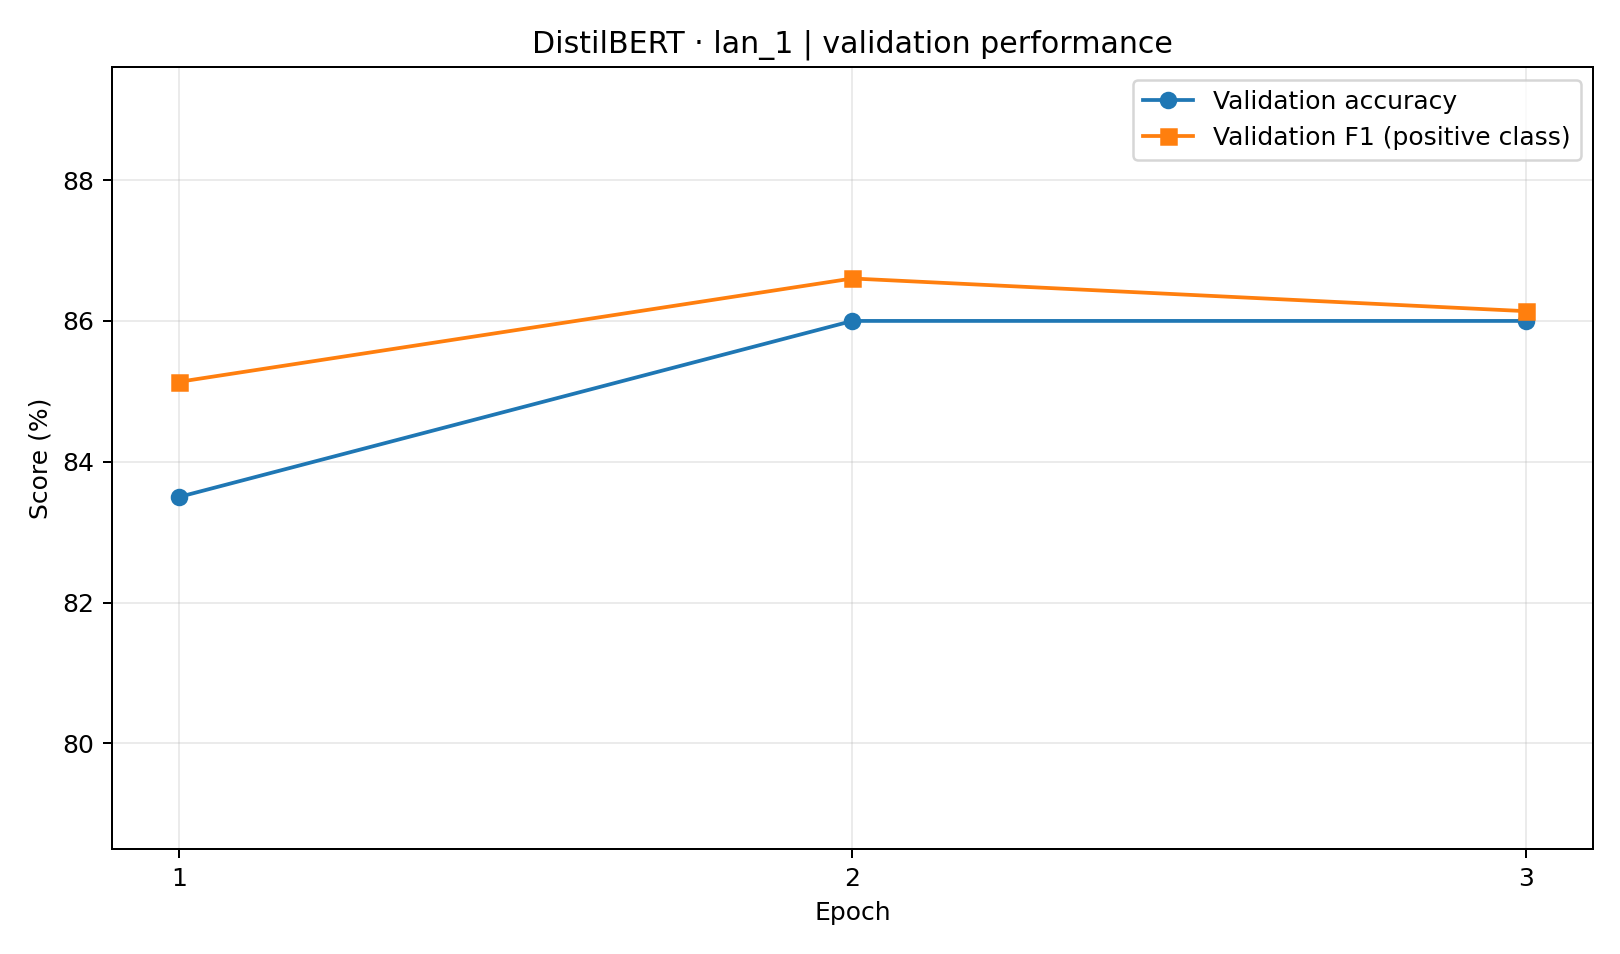

**confusion_matrix.png**

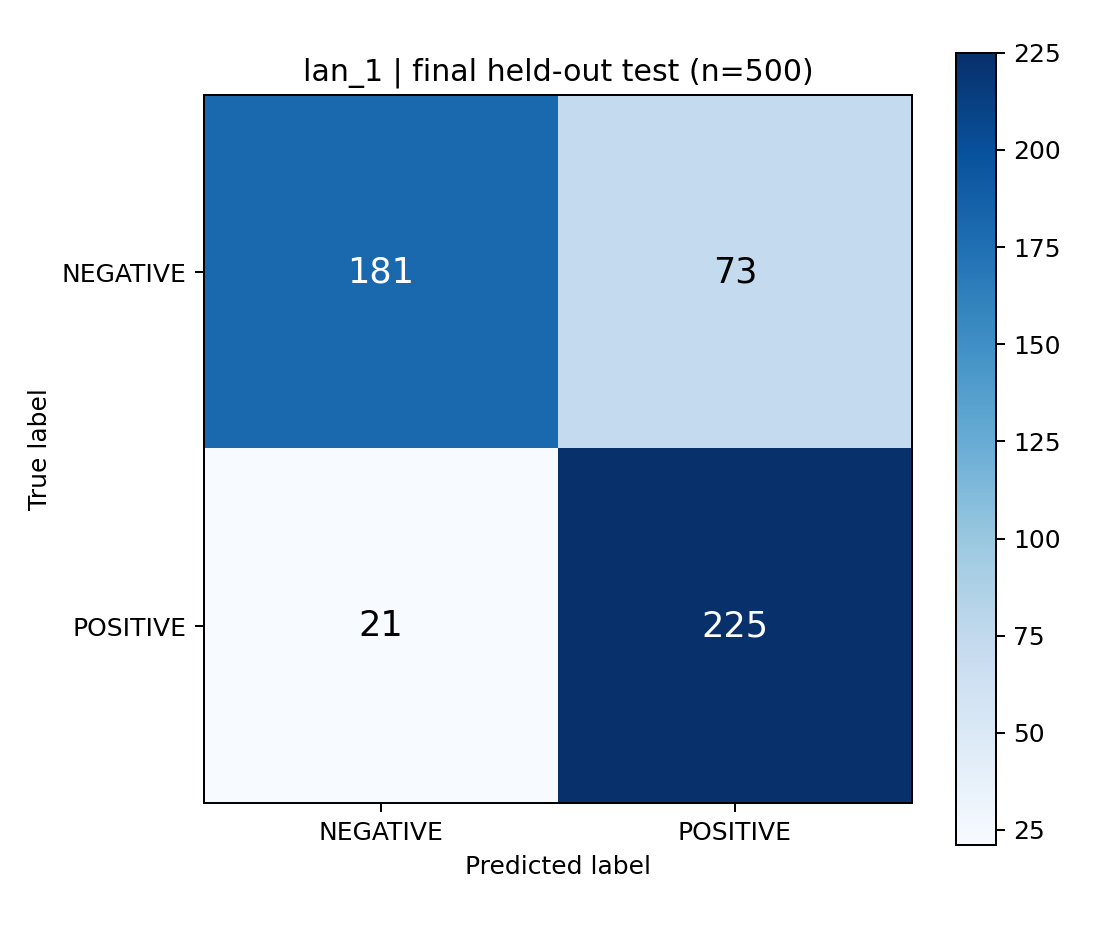

In [6]:
images = ROOT / 'visualization' / RUN
for name in ['loss.png','validation_scores.png','confusion_matrix.png']:
    p = images / name
    if p.exists():
        display(Markdown('**'+name+'**'))
        display(Image(filename=str(p)))
    else: print('Not generated:',name)


## 8. Interpretation and limitations

**1. Validation performance and overfitting**

Validation F1 rose from 85.14% at epoch 1 to 86.60% at epoch 2, then fell to 86.14% at epoch 3. Training loss kept decreasing (0.5190 → 0.2794 → 0.1776) while validation loss increased (0.3903 → 0.4314 → 0.5080). This is consistent with overfitting after the first epochs. Epoch 2 was selected as the best checkpoint by validation F1 (86.60%), even though validation loss was lowest at epoch 1.

**2. Classification errors and class performance**

On the final test set the model has higher recall for POSITIVE reviews (91.46%) than for NEGATIVE reviews (71.26%). The confusion matrix shows 181 NEGATIVE and 225 POSITIVE reviews classified correctly, 73 NEGATIVE reviews wrongly labeled POSITIVE (false positives) and 21 POSITIVE reviews wrongly labeled NEGATIVE (false negatives). The model therefore leans toward predicting POSITIVE.

**3. Token truncation**

Reviews are cut at 128 tokens to reduce memory and time. Longer IMDb reviews may lose sentiment cues, especially near the end, which can affect accuracy.

**4. Hyperparameter selection and test independence**

The configuration (learning rate 2e-5, batch size 8, 3 epochs, weight decay 0.01) was fixed in advance and the checkpoint was selected on validation F1. The test set was evaluated once, after validation, and was not used to choose the model or hyperparameters.

**5. Generalization limitations**

Only 2,000 training, 400 validation and 500 test reviews were used, with one seed (42). Test accuracy (81.20%) is 4.80 percentage points below validation accuracy (86.00%). With 500 test reviews the standard error of accuracy is about 1.7 percentage points, so small differences are not meaningful. An earlier run of the same configuration on another machine gave 84.00% test accuracy, which shows that results vary between runs even with the same seed. Results may not transfer to full IMDb or to other domains.

**Conclusion**

The fine-tuned DistilBERT model reached **81.20% test accuracy**, **82.72% positive-class F1** and **0.9165 ROC-AUC** on 500 held-out IMDb reviews, far above the majority-class baseline (50.80% accuracy). Compared with the zero-shot SST-2 classifier (81.80% accuracy, 81.39% F1), the fine-tuned model has 0.60 points lower accuracy and 1.33 points higher F1, so in this run fine-tuning shows no clear advantage over the zero-shot model; both differences are within sampling noise. Overfitting indicators, the small data size and the single seed should be kept in mind.
